# The Midterm Elections as an Event — Industry First, Then Movers, Conditioned on Expectations

**Method (same machinery as the earnings work).** Eight midterms, 1994–2022. Every return is an adjusted-close total return measured off the pre-election closes: run-up = the 5 sessions ending the Monday before the vote; **reaction = Wednesday close vs Tuesday close** (results land Tuesday night, so Wednesday is the reaction session); then +5d / +20d / +60d from the Monday close, plus post-reaction drift. Prices respond to the **surprise vs the priced trajectory**, not to the outcome label — so every cut is run twice: by *outcome* (who controls Congress) and by *expectation* (was the result the priced one?).

**Small-n discipline.** Eight cycles; sector SPDRs exist only from 2002 (n=6), several vehicles from 2006–2010. Cells of n=1–4 are distributions, not means to trade on. Grades: **REPEATS** = same direction in ≥3 cycles; **STORY** = one clean cycle + a mechanism; **PRICED** = the move is in the run-up, not the reaction.

**Prior work.** This extends the n=4 study in `research/election_complex_2026-10-30.md` (2010–2022) to the full sample and ends with verdicts on its two unruled specs, E-1 and E-2.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, yfinance as yf
import matplotlib.pyplot as plt
pd.set_option("display.width", 220)

# STEP 0 — the events and what was expected going in.
# Expectation classes are chamber-level, from the contemporary record (generic ballot,
# forecast models, prediction markets, post-election post-mortems). Sources in the notes.
CYCLES = [
 (1994,"1994-11-08","D","R take (+54)","R take (+8)","R Congress","SURPRISE-R","SURPRISE-R","SURPRISE",
  "R gains expected on a flipped generic ballot, but eve consensus was R falls short of majorities in BOTH chambers; only 3 of 14 WaPo-polled experts predicted the House flip; +54 seats far exceeded expectations."),
 (1998,"1998-11-03","D","R hold (D +5)","R hold (no net change)","R Congress","SURPRISE-D","EXPECTED","SURPRISE",
  "Six-year itch + impeachment: R gains expected (Gingrich predicted pickups); Democrats GAINED 5 House seats - first president's-party House gain in a midterm since 1934; Gingrich resigned."),
 (2002,"2002-11-05","R","R hold (+8)","R take (+2 net)","Unified R","EXPECTED","SURPRISE-R","SURPRISE",
  "Post-9/11 rally, Bush ~63% approval: House hold expected and delivered; Senate control a genuine toss-up after the Jeffords switch - R retake a mild surprise."),
 (2006,"2006-11-07","R","D take (+31)","D take (+6)","D Congress","EXPECTED","EXPECTED","EXPECTED",
  "Generic ballot D+11 average; the D wave was the consensus call all fall; models if anything underestimated it (+31 vs +15-20 projected)."),
 (2010,"2010-11-02","D","R take (+63)","D hold","Split","EXPECTED","EXPECTED","EXPECTED",
  "Generic ballot R+9; R House take the consensus (models +40-50, actual +63); D Senate hold was the modal forecast."),
 (2014,"2014-11-04","D","R hold (+13)","R take (+9)","R Congress","EXPECTED","EXPECTED","EXPECTED",
  "Forecast models favored the R Senate take (~2/3-3/4 probability); generic ballot R+3; the best-calibrated modern midterm."),
 (2018,"2018-11-06","R","D take (+41)","R hold (+2)","Split","EXPECTED","EXPECTED","EXPECTED",
  "Generic ballot D+7-8; D House take and R Senate hold/gain were both the consensus forecast (26 D Senate seats defended)."),
 (2022,"2022-11-08","D","R take (+9)","D hold (+1)","Split","EXPECTED","SURPRISE-D","SURPRISE",
  "The red wave that failed: 538's final forecast gave R 59% Senate / 84% House; prediction markets ~33% for a D Senate hold. D held the Senate and gained a seat; R House gain +9 vs +20-30 projected."),
]
cyc = pd.DataFrame(CYCLES, columns=["cycle","election_date","president_party","house_result","senate_result",
                                    "government","house_expectation","senate_expectation","expectation_class","expectation_note"])
cyc.to_csv("cycles.csv", index=False)
cyc[["cycle","election_date","president_party","house_result","senate_result","government","expectation_class"]]

,cycle,election_date,president_party,house_result,senate_result,government,expectation_class
0,1994,1994-11-08,D,R take (+54),R take (+8),R Congress,SURPRISE
1,1998,1998-11-03,D,R hold (D +5),R hold (no net change),R Congress,SURPRISE
2,2002,2002-11-05,R,R hold (+8),R take (+2 net),Unified R,SURPRISE
3,2006,2006-11-07,R,D take (+31),D take (+6),D Congress,EXPECTED
4,2010,2010-11-02,D,R take (+63),D hold,Split,EXPECTED
5,2014,2014-11-04,D,R hold (+13),R take (+9),R Congress,EXPECTED
6,2018,2018-11-06,R,D take (+41),R hold (+2),Split,EXPECTED
7,2022,2022-11-08,D,R take (+9),D hold (+1),Split,SURPRISE


**Two classification calls worth flagging.** (1) **1994 is a SURPRISE cycle, not an expected one.** The generic ballot had flipped Republican and big R *gains* were expected — but the eve consensus was that Republicans would fall short of majorities in both chambers; the double flip and the 54-seat magnitude stunned the forecasters (a Washington Post poll of 14 experts found 3 predicting a House takeover). Direction expected, control a surprise. (2) **2022's House flip was expected (84%); its Senate hold was the surprise.** The cycle class follows the chamber that carried the surprise.

In [2]:
INDEX   = ["SPY","QQQ","IWM","DIA"]
SECTORS = ["XLK","XLF","XLE","XLV","XLI","XLP","XLY","XLU","XLB","XLRE","KBE","XOP","ITA","IHF","XHB","TAN","ICLN"]
MOVERS  = ["XOM","CVX","SLB","OXY","HAL","COP","UNH","HUM","CI","LLY","JNJ","PFE","CVS",
           "LMT","RTX","NOC","GD","BA","JPM","BAC","GS","WFC","C","FSLR","ENPH","NEE"]
ALL = sorted(set(INDEX+SECTORS+MOVERS+["CL=F"]))
try:
    px = pd.read_csv("prices.csv", index_col=0, parse_dates=True)
    assert set(ALL) <= set(px.columns)
except Exception:
    px = yf.download(ALL, start="1993-09-01", end="2023-05-01", auto_adjust=True, progress=False)["Close"]
    px.to_csv("prices.csv")
EDATES = {r.cycle: pd.Timestamp(r.election_date) for r in cyc.itertuples()}

def windows(series, edate):
    s = series.dropna()
    pos = s.index.get_indexer([edate], method="ffill")[0]
    if pos < 6 or pos + 61 >= len(s): return None
    c = s.iloc; base = c[pos-1]
    return dict(runup=c[pos-1]/c[pos-6]-1, wed=c[pos+1]/c[pos]-1, wedcum=c[pos+1]/base-1,
                p5=c[pos+5]/base-1, p20=c[pos+20]/base-1, p60=c[pos+60]/base-1,
                drift20=c[pos+20]/c[pos+1]-1, drift60=c[pos+60]/c[pos+1]-1)

recs = []
for tk in ALL:
    for yr, ed in EDATES.items():
        w = windows(px[tk], ed)
        if w: recs.append(dict(ticker=tk, cycle=yr, **{k: round(v*100,2) for k,v in w.items()}))
W = pd.DataFrame(recs).join(cyc.set_index("cycle")[["government","expectation_class"]], on="cycle")
spy = W[W.ticker=="SPY"].set_index("cycle")
spy[["runup","wed","p5","p20","p60","drift60","government","expectation_class"]]

,runup,wed,p5,p20,p60,drift60,government,expectation_class
cycle,,,,,,,,
1994,-2.14,0.17,0.47,-2.49,4.19,3.21,R Congress,SURPRISE
1998,3.95,1.07,1.01,4.83,13.81,13.43,R Congress,SURPRISE
2002,1.70,1.30,-2.38,1.45,-4.91,-6.86,Unified R,SURPRISE
2006,0.20,0.22,1.12,2.68,5.52,4.89,D Congress,EXPECTED
2010,-0.14,0.40,2.60,2.09,8.32,7.04,Split,EXPECTED
2014,2.86,0.63,1.19,3.03,0.63,0.34,R Congress,EXPECTED
2018,3.61,2.14,-0.49,-1.30,0.48,-2.25,Split,EXPECTED
2022,-1.62,-2.06,4.88,3.48,8.36,10.05,Split,SURPRISE


## STEP 1a — The index verdict: the winner's identity does not move the index

SPY's Wednesday reaction is positive in **7 of 8** cycles (mean +0.48%) and the +60d window is positive in **7 of 8** (mean +4.55%) — under **every** outcome class: R-favorable cycles +3.4 at +60d, the D-Congress cycle +5.5, split cycles +5.7. The only negative +60 is 2002 (−4.9), an Iraq-discount winter, not a verdict on the R Senate. What the outcome determines is *dispersion*, not direction — and that runs through the expectation axis: surprise cycles show SPY |Wednesday| of 1.15% vs 0.85% for expected cycles, and sector-level |Wednesday vs SPY| of **1.09% vs 0.75% (+45%)**. At the index level neither grouping explains direction (variance share η² ≈ 0.10 for outcome, 0.10 for expectation on Wednesday; ≈ 0.00–0.03 at +20d).

**Confounds, named:** the +60 window's mean leans on 1998 (+13.8 — the dot-com winter) and 2022 (+8.4 — the post-CPI bear-market rally), and 2018's ≈ +0.5 endpoint hides a **−14.3% intra-window drawdown** (the Dec 2018 selloff). The post-midterm drift is real; the path is not a free ride.

ALL CYCLES    {'wed': 'n=8 mean +0.48 med +0.52 hit 88%', 'p5': 'n=8 mean +1.05 med +1.06 hit 75%', 'p20': 'n=8 mean +1.72 med +2.38 hit 75%', 'p60': 'n=8 mean +4.55 med +4.86 hit 88%'}
GOVT D Congress  {'wed': 'n=1 mean +0.22 med +0.22 hit 100%', 'p5': 'n=1 mean +1.12 med +1.12 hit 100%', 'p20': 'n=1 mean +2.68 med +2.68 hit 100%', 'p60': 'n=1 mean +5.52 med +5.52 hit 100%'}
GOVT R Congress  {'wed': 'n=3 mean +0.62 med +0.63 hit 100%', 'p5': 'n=3 mean +0.89 med +1.01 hit 100%', 'p20': 'n=3 mean +1.79 med +3.03 hit 67%', 'p60': 'n=3 mean +6.21 med +4.19 hit 100%'}
GOVT Split       {'wed': 'n=3 mean +0.16 med +0.40 hit 67%', 'p5': 'n=3 mean +2.33 med +2.60 hit 67%', 'p20': 'n=3 mean +1.42 med +2.09 hit 67%', 'p60': 'n=3 mean +5.72 med +8.32 hit 100%'}
GOVT Unified R   {'wed': 'n=1 mean +1.30 med +1.30 hit 100%', 'p5': 'n=1 mean -2.38 med -2.38 hit 0%', 'p20': 'n=1 mean +1.45 med +1.45 hit 100%', 'p60': 'n=1 mean -4.91 med -4.91 hit 0%'}
EXP  EXPECTED    {'wed': 'n=4 mean +0.85 med +0.52

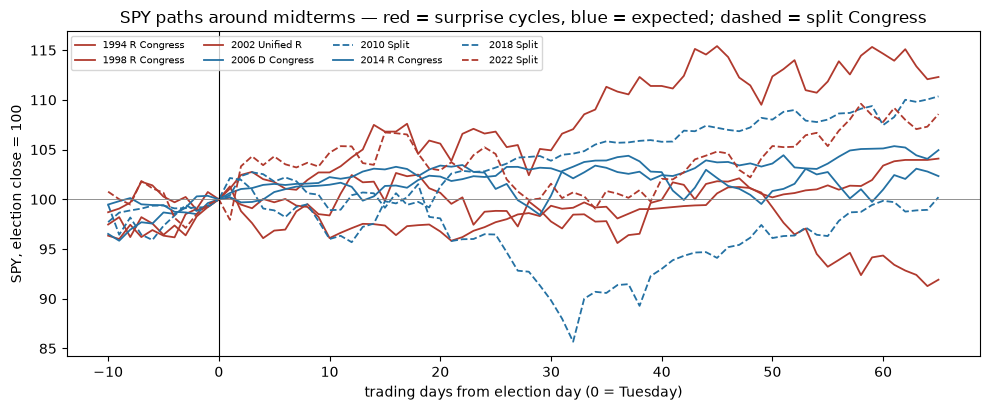

In [3]:
def stats(df, cols=("wed","p5","p20","p60")):
    rows = {}
    for c in cols:
        s = df[c].dropna()
        rows[c] = f"n={len(s)} mean {s.mean():+.2f} med {s.median():+.2f} hit {(s>0).mean()*100:.0f}%"
    return rows
print("ALL CYCLES   ", stats(spy))
for k, g in spy.groupby("government"): print(f"GOVT {k:11s}", stats(g))
for k, g in spy.groupby("expectation_class"): print(f"EXP  {k:11s}", stats(g))
def eta2(s, groups):
    s = s.dropna(); groups = groups.loc[s.index]
    tot = ((s-s.mean())**2).sum()
    return round(sum(len(g)*(g.mean()-s.mean())**2 for _, g in s.groupby(groups))/tot, 3)
print("eta2 Wed: outcome", eta2(spy.wed, spy.government), "| expectation", eta2(spy.wed, spy.expectation_class))
print("eta2 +20: outcome", eta2(spy.p20, spy.government), "| expectation", eta2(spy.p20, spy.expectation_class))
print("mean |Wed| surprise", round(spy[spy.expectation_class=='SURPRISE'].wed.abs().mean(),2),
      "vs expected", round(spy[spy.expectation_class=='EXPECTED'].wed.abs().mean(),2))

fig, ax = plt.subplots(figsize=(10, 4.2))
for r in cyc.itertuples():
    s = px["SPY"].dropna(); pos = s.index.get_indexer([pd.Timestamp(r.election_date)], method="ffill")[0]
    seg = s.iloc[pos-10:pos+66]; seg = seg/seg.iloc[10]*100
    ax.plot(range(-10, 66), seg.values, lw=1.3,
            color=("#b03a2e" if r.expectation_class=="SURPRISE" else "#2471a3"),
            ls=("--" if r.government=="Split" else "-"), label=f"{r.cycle} {r.government}")
ax.axvline(0, color="k", lw=0.8); ax.axhline(100, color="grey", lw=0.6)
ax.set_xlabel("trading days from election day (0 = Tuesday)"); ax.set_ylabel("SPY, election close = 100")
ax.set_title("SPY paths around midterms — red = surprise cycles, blue = expected; dashed = split Congress")
ax.legend(fontsize=7, ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

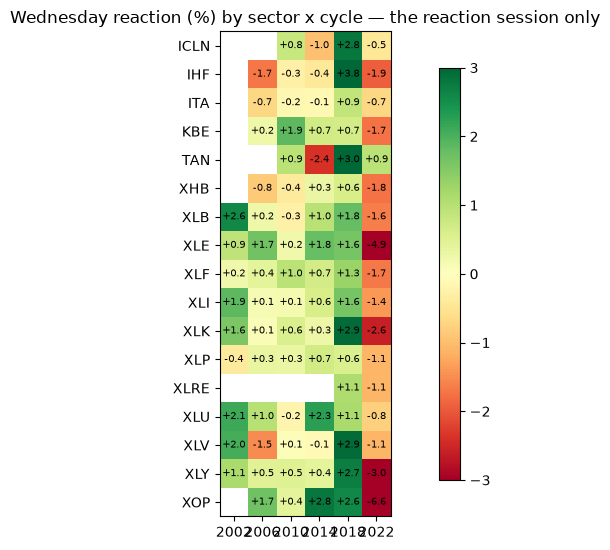

cycle,2002,2006,2010,2014,2018,2022
ticker,,,,,,
ICLN,NaN,NaN,0.82,-0.97,2.81,-0.46
IHF,NaN,-1.70,-0.27,-0.42,3.79,-1.93
ITA,NaN,-0.68,-0.16,-0.13,0.87,-0.68
KBE,NaN,0.25,1.87,0.70,0.66,-1.74
TAN,NaN,NaN,0.95,-2.39,3.04,0.95
XHB,NaN,-0.85,-0.38,0.32,0.62,-1.75
XLB,2.60,0.24,-0.28,0.97,1.80,-1.62
XLE,0.90,1.68,0.22,1.76,1.64,-4.89
XLF,0.22,0.42,0.96,0.67,1.30,-1.68


In [4]:
sec = W[W.ticker.isin(SECTORS)].copy()
spyw = spy[["wed","p5","p20"]].rename(columns={"wed":"spy_wed","p5":"spy_p5","p20":"spy_p20"})
sec = sec.join(spyw, on="cycle")
sec["wed_rel"] = (sec.wed - sec.spy_wed).round(2); sec["p5_rel"] = (sec.p5 - sec.spy_p5).round(2); sec["p20_rel"] = (sec.p20 - sec.spy_p20).round(2)
sec.to_csv("sector_windows.csv", index=False)
piv = sec.pivot_table(index="ticker", columns="cycle", values="wed")
fig, ax = plt.subplots(figsize=(10, 5.6))
im = ax.imshow(piv.values, cmap="RdYlGn", vmin=-3, vmax=3)
ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Wednesday reaction (%) by sector x cycle — the reaction session only")
plt.colorbar(im, shrink=0.85); plt.tight_layout(); plt.show()
piv.round(2)

## STEP 1b — Sector grades (Wednesday reaction unless noted)

| Pattern | Evidence | Grade |
|---|---|---|
| **Financials get the resolution bid when the outcome is the expected one** | KBE Wed positive in **4 of 4** expected cycles (mean +0.87); XLF Wed positive 5 of 6 overall; KBE Tue→Fri positive in all 5 SPDR-era cycles (+0.05 / +7.85* / +1.65 / +0.23 / +2.85). *2010 is QE2-inflated. | **REPEATS** |
| **Defense has no election beta** | ITA Wed mean −0.16, positive 1 of 5, mean rel −0.42. Confirms the n=4 null at n=5. | **REPEATS (a null)** |
| **Clean energy pays under a unified R Congress** | 2014: TAN Wed −2.39, +20d rel −11.39; FSLR +5d −12.6. One cycle only — but the mechanism (subsidy/regulatory repricing) is direct. Mirror long in D years is NOT supported (TAN fades at +20d in split years too, rel −2.67). | **STORY** |
| **Managed care: real policy beta, sign = which tail dies** | D-take 2006: UNH Wed −3.17 (−6.98 thru Fri), HUM −5.90, XLV −1.51 — the sample's cleanest policy print. Split cycles: UNH Wed −0.92 / +4.21 / −2.24 (mean +0.35) — 2018's relief is one observation, not a pattern. | **STORY** |
| **Small caps lag Wednesday** | IWM−SPY Wed rel: +0.40 / +0.29 / −0.01 / −0.45 / −0.35 / −0.69 → lagged 4 of 6, mean −0.13. The n=4 study's "lagged all four" softens; the folklore *bid* is still absent. | **STORY (downgraded)** |
| **Utilities catch a Wednesday bid** | XLU Wed mean +0.92, positive 4 of 6, strongest in R-Congress cycles (+2.11, +2.26) — reads as a resolution/duration bid, not a party trade (2002 is Enron-rebound contaminated). | **STORY (lean)** |
| **Energy by outcome** | No pattern — see the oil decomposition below. XLE Wed positive 5 of 6 but tracks crude; +20d rel negative in every class. | **PRICED / oil's, not Congress's** |

Everything not in this table graded to ≈ zero: no sector shows a reliable *winner-identity* Wednesday effect once the expectation cut is applied. The two cuts interact exactly as the doctrine predicts: outcome labels sort the past; expectation classes sort the *size* of the move.

In [5]:
mov = W[W.ticker.isin(MOVERS)].copy().join(spyw, on="cycle")
mov["wed_rel"] = (mov.wed - mov.spy_wed).round(2); mov["p5_rel"] = (mov.p5 - mov.spy_p5).round(2)
mov.to_csv("movers.csv", index=False)
for yr, g in mov.groupby("cycle"):
    g = g.dropna(subset=["wed_rel"])
    f = lambda r: f"{r.ticker} {r.wed_rel:+.1f}"
    print(yr, g.government.iloc[0], "| up:", ", ".join(map(f, g.nlargest(3,'wed_rel').itertuples())),
          "| dn:", ", ".join(map(f, g.nsmallest(3,'wed_rel').itertuples())))
print()
for tk in ["XOM","LMT","FSLR","UNH","JPM"]:
    g = mov[mov.ticker==tk]
    print(tk, " | ".join(f"{int(r.cycle)}: runup {r.runup:+.1f}, Wed {r.wed:+.1f} (rel {r.wed_rel:+.1f}), +5rel {r.p5_rel:+.1f}" for r in g.itertuples()))

1994 R Congress | up: NOC +2.7, CI +2.4, PFE +2.2 | dn: CVX -2.5, COP -2.3, C -1.3
1998 R Congress | up: BAC +2.8, NOC +2.8, JPM +2.0 | dn: HUM -6.6, CVS -4.0, PFE -3.9
2002 Unified R | up: HAL +9.0, BA +5.2, LLY +3.1 | dn: WFC -3.4, JPM -3.1, XOM -2.6
2006 D Congress | up: OXY +2.6, NEE +2.1, COP +2.0 | dn: HUM -6.1, UNH -3.4, CI -2.5
2010 Split | up: WFC +1.7, JPM +1.7, CVS +0.7 | dn: HUM -2.2, LMT -1.4, UNH -1.3
2014 R Congress | up: NEE +3.2, SLB +2.0, CVS +1.8 | dn: ENPH -23.4, FSLR -1.7, CI -1.6
2018 Split | up: ENPH +7.4, HUM +4.5, UNH +2.1 | dn: WFC -2.1, SLB -1.7, OXY -1.6
2022 Split | up: FSLR +4.7, ENPH +3.7, NEE +2.0 | dn: OXY -7.2, COP -4.8, HAL -4.4

XOM 1994: runup -1.6, Wed -0.8 (rel -1.0), +5rel -2.5 | 1998: runup +1.2, Wed -1.4 (rel -2.4), +5rel -3.1 | 2002: runup -1.1, Wed -1.3 (rel -2.6), +5rel +2.4 | 2006: runup +2.9, Wed +2.2 (rel +2.0), +5rel +1.4 | 2010: runup +1.1, Wed +0.2 (rel -0.2), +5rel +3.6 | 2014: runup +1.6, Wed +0.6 (rel -0.1), +5rel +0.8 | 2018: runup

## STEP 2 — Biggest movers, and the narrative audit

**Read the movers table with the confound filter on.** The single biggest "election mover" in the sample is neither: **ENPH −22.8% on the Wednesday of 2014 was its own earnings print** (reported that day), and HAL's +10.3% Wednesday in 2002 was an asbestos-overhang name resolving name-specifically. Earnings season overlaps every midterm — the same lesson as the earnings book, one level up.

**The narrative trades, audited:**
- **"R win → energy up": fails.** XOM's Wednesday was *negative* in all three R-favorable surprise cycles (rel −1.0 / −2.4 / −2.6) and its best R-cycle Wednesday (+0.6 abs, 2014) is a rounding error. CVX the same. What energy did in election weeks is what oil did (next section).
- **"R win → defense up": fails at the leader level too.** LMT Wed rel was negative in 5 of 8 cycles including R wins in 2010 and 2014; the one big defense print (BA +6.5 abs in 2002) is an Iraq-war buildup tape, not a midterm effect. ITA's null (Step 1) is the honest summary.
- **"D win → clean energy up": half.** FSLR/ENPH did lead the 2022 Wednesday (rel +4.7 / +3.7) — but 2022 was a *surprise-D* night; on the *expected* D night (2006, pre-TAN/FSLR data) there is no clean-energy vehicle to check, and 2018's split saw ENPH +9.5 abs on its own momentum. The trade that printed is "surprise → the surprise's sector," not "D → solar."
- **"Managed care down when D wins": the one narrative that printed clean.** 2006: HUM −5.9, UNH −3.2 Wed (rel −6.1 / −3.4). And its mirror — relief when the unified-government tail dies — printed exactly once, 2018 (UNH +4.21, HUM +6.68 abs). Policy beta in this complex is real; it is also rare, because it needs a chamber flip or a credible flip scare.
- **Banks:** JPM's Wednesday was positive in 5 of 8 cycles (incl. +3.11 in 1998) — but the *class* pattern (Step 1) is the resolution bid in expected cycles, not an R-party bid: banks fell Wednesday in 2002 (JPM rel −3.1) on an R Senate take.

       xle_wed  oil_wed  xle_p5  oil_p5  government
cycle                                              
2002      0.90    -1.42   -1.10   -3.90   Unified R
2006      1.68     1.53    1.19   -2.90  D Congress
2010      0.22     0.94    5.18    4.54       Split
2014      1.76     1.93    1.42   -1.07  R Congress
2018      1.64    -0.87   -4.59  -11.74       Split
2022     -4.89    -3.46    1.17   -5.31       Split
corr Wed: 0.78 | corr +5d: 0.95
all-weeks 2002-2022 benchmark: weekly XLE~oil corr 0.58 (R2 0.33, n=1096)
2002: trailing beta 0.31 | XLE +5d -1.10 = oil-explained -1.19 + residual +0.09  (Unified R)
2006: trailing beta 0.57 | XLE +5d +1.19 = oil-explained -1.66 + residual +2.85  (D Congress)
2010: trailing beta 0.58 | XLE +5d +5.18 = oil-explained +2.62 + residual +2.56  (Split)
2014: trailing beta 0.35 | XLE +5d +1.42 = oil-explained -0.37 + residual +1.79  (R Congress)
2018: trailing beta 0.49 | XLE +5d -4.59 = oil-explained -5.78 + residual +1.19  (Split)
2022: trailing beta

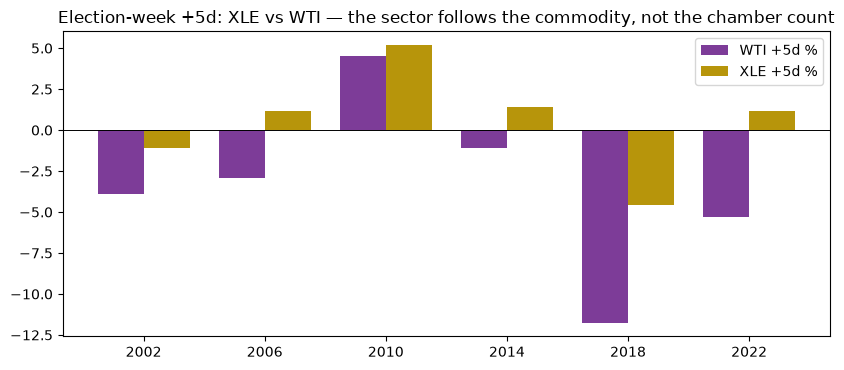

In [6]:
oil = W[W.ticker=="CL=F"].set_index("cycle"); xle = W[W.ticker=="XLE"].set_index("cycle")
both = pd.DataFrame({"xle_wed": xle.wed, "oil_wed": oil.wed, "xle_p5": xle.p5, "oil_p5": oil.p5,
                     "government": xle.government}).dropna()
print(both.round(2).to_string())
print("corr Wed:", round(both.xle_wed.corr(both.oil_wed), 2), "| corr +5d:", round(both.xle_p5.corr(both.oil_p5), 2))
wk = px[["XLE","CL=F"]].dropna().resample("W-FRI").last().pct_change().dropna()
wk = wk[(wk.index>="2002-01-01") & (wk.index<="2022-12-31")]
print(f"all-weeks 2002-2022 benchmark: weekly XLE~oil corr {wk.XLE.corr(wk['CL=F']):.2f} (R2 {wk.XLE.corr(wk['CL=F'])**2:.2f}, n={len(wk)})")
for yr in both.index:
    s = px[["XLE","CL=F"]].dropna(); pos = s.index.get_indexer([EDATES[yr]], method="ffill")[0]
    tr = s.iloc[max(0,pos-260):pos-5].pct_change().dropna()
    beta = tr.XLE.cov(tr["CL=F"])/tr["CL=F"].var()
    print(f"{yr}: trailing beta {beta:.2f} | XLE +5d {both.loc[yr,'xle_p5']:+.2f} = oil-explained {beta*both.loc[yr,'oil_p5']:+.2f} + residual {both.loc[yr,'xle_p5']-beta*both.loc[yr,'oil_p5']:+.2f}  ({both.loc[yr,'government']})")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(both)); w_ = 0.38
ax.bar(x-w_/2, both.oil_p5, w_, label="WTI +5d %", color="#7d3c98"); ax.bar(x+w_/2, both.xle_p5, w_, label="XLE +5d %", color="#b7950b")
ax.axhline(0, color="k", lw=0.7); ax.set_xticks(x, both.index); ax.legend()
ax.set_title("Election-week +5d: XLE vs WTI — the sector follows the commodity, not the chamber count")
plt.tight_layout(); plt.show()

## The energy–war hypothesis, answered directly

Kevin's hypothesis: *Republicans win → the war continues → energy keeps rising.* In-sample, it fails on both legs. **Leg 1 (R wins lift energy):** the two R-Congress Wednesdays printed XLE +0.90 / +1.76 with WTI at −1.42 / +1.93 — oil's coin flips, not a congressional bid; the largest XLE Wednesday of the sample is **−4.89 (2022)**, tracking a −3.46 oil day in a split/surprise week. **Leg 2 (the mechanism):** across the six SPDR-era cycles, XLE's +5d return correlates **0.95** with WTI's +5d return; oil-beta residuals are mildly positive in *all six* cycles (+0.1 to +3.6) — in R, D, and split years alike, i.e. classless, and within trailing-beta estimation noise. Against the all-weeks benchmark (weekly XLE~oil R² = 0.33 over 2002–2022), election weeks are if anything *more* oil-dominated, not less. **The election has never explained a meaningful share of XLE's election-week variance once oil is in the regression.**

**The 2026 confound, stated plainly:** the book's ~$287k energy sleeve is a Brent position — front-month in the mid-$110s on the Hormuz supply shock (limpet-mine strike, strike-option briefings, OPEC+ on Sunday). A Senate result does not move Hormuz. Whatever XLE does Wed–Fri next week will be Brent's move wearing, at most, an election ribbon — and the sleeve already owns both directions of that exposure. There is no midterm energy trade to add.

## Falsification — the study against itself

1. **"Who won moves the index" — falsified in-sample.** +60d is positive under every outcome class (R +3.4 / D +5.5 / split +5.7 means). Any index-direction claim by winner is dead; what survives is a winner-agnostic resolution bid + year-end seasonality, confounded as logged.
2. **Expectation-over-outcome, refined not crowned.** On index *direction* the two groupings tie (η² ≈ 0.10 each, both ≈ noise). The doctrine survives only in its amplitude form: surprise cycles produce ~45% larger sector dispersion. If 2026's surprise branch (split or R sweep) prints sector |Wed rel| dispersion *below* the expected-cycle norm (~0.75), the amplitude claim dies too.
3. **Banks-resolution bid — live test in 2026.** The priced base case (Dem sweep) is an "expected" outcome, the exact cell with the 4/4 record. A negative KBE Wednesday on a confirmed-as-priced sweep breaks it.
4. **E-1's gate logic.** One historical firing, one success (2018). A future in-band XLV gap on a confirmed split that is *down* through Friday makes it 1-of-2 and kills the spec.
5. **The +60 drift.** Positive 7/8 — but if the next two cycles print negative +60s in split/expected cells, the seasonality claim degrades to "1998–2022 regime artifact." The 2018 path (−14.3% intra-window) already falsifies the *low-risk* version of it.

## STEP 3 — The 2026 map

**Priced state, verified Oct 31, 2026 (Polymarket/Kalshi, cross-checked):** Democrats Sweep **~71%** · split (D House / R Senate) **~24%** · Republican Sweep **~5%** · D Senate/R House ~1%. D House ~94–95%, D Senate ~71–72%; the 51st Senate seat runs through Maine (Jackson D ~68–69%). Vs the Oct 30 file: the sweep has drifted *up* (66→71), the split *down* (28→24) — the surprise branch got slightly more surprising. Generic ballot ≈ D+8. The president's party is R, approval ~39%, and an unpopular war is in the tape — the structural setup resembles 2006/2018 (out-party wave, expected) far more than 2022 (out-party wave, failed).

### Branch playbook (evidence-graded)

| 2026 outcome (priced) | What the study says moves | Window | Sign | Grade |
|---|---|---|---|---|
| **Dem sweep (~71%)** — the priced base | Banks get the resolution bid anyway (winner-agnostic, expected-cycle cell); managed care carries the 2006-style policy-beta risk (UNH/HUM were the D-take losers); clean energy's bid is priced and follow-through historically fades at +20d | Wed | KBE +; XLV-managed-care − tilt; TAN/ICLN ≈ 0 after Wed | REPEATS (banks) / STORY (managed care) |
| **Split — R holds Senate (~24%)** — the genuine surprise | Healthcare relief (both tails die) is the one surprise-sector trade with a clean precedent (2018: XLV +2.94 Wed, +2.70 thru Fri; UNH +4.21/+4.94). Crowded sweep hedges (clean energy) unwind mildly | Wed→Fri | XLV + (gap-gated) | STORY |
| **R sweep (~5%)** — the tail | Banks on reconciliation optionality (capital relief becomes *passable* — the only branch with a live legislative channel); clean energy is the short side with +20d evidence; rates revolt is the governor | Wed (+20d for clean) | KBE +; TAN/ICLN − | STORY |
| **Status quo R/R (~0% priced as such; R House hold is ~5-6%)** | A Republican House hold inside a D Senate night (or vice versa) is an off-menu surprise: treat as unresolved-grade uncertainty, index vol only | Wed | — | no precedent |
| **Senate unresolved Wed** | Nothing resolves sectorally; historical Wednesdays with late counts are index-vol events | Wed–Thu | vol only | — |

### Verdict on E-1 (split → long XLV $30–40k, only if Wed gap +1.0% to +3.5%, out Fri): **SURVIVES, levels unchanged.**
The full sample shows raw split-relief is a coin flip (XLV Wed in split cycles: +0.06 / +2.94 / −1.08) — and that the **gap gate is the trade**: it fires only in 2018, the one cycle that paid (+2.70% through Friday), and refuses both duds. The mechanism got *stronger* support from the other side of the ledger (2006 proves this complex has real chamber-flip beta: UNH −6.98 through the Friday of a D take). Evidence grade stays STORY — one clean firing — so the size and the halve-at-top-of-band rule stand as written. The 2026 split is marginally more surprising than when the spec was drafted (24% vs 28%), which helps the asymmetry, not the base rate.

### Verdict on E-2 (R sweep → long KBE $25–35k if banks gap ≥ +1.5%, killed if 10y gaps +15bp): **SURVIVES, gate kept, size at the $25k low end.**
Honest demerit, recorded: at ETF level the +1.5% gate would have fired in **zero** historical R-win cycles (2014 KBE Wed +0.70; 2002 XLF +0.22) — because every in-sample R sweep was *expected* and priced quietly into the vote. A 5%-priced 2026 R sweep is a different animal: the surprise cycles are where multi-point sector Wednesdays live (2022: FSLR rel +4.7, XLE −4.89 abs). The gate is a surprise-confirmation device, and +1.5% is the right height for one. Two hard addenda from the full sample: (1) KBE's +20d relative return is negative in **every** outcome class (mean −3.24) — the Friday exit is structural, and **E-2 must not migrate into the post-comp book as a drift hold**; (2) the +15bp rates governor never bound in-sample — it stays as insurance, unproven either way.

### NEW — E-6 candidate (for Kevin's ruling; not an amendment by stealth): the resolution bid in the priced branch
The full sample's cleanest sector fact is winner-agnostic: **when the outcome is the expected one, banks are bid on Wednesday** (KBE 4/4 expected cycles, Wed mean +0.87; Tue→Fri positive in all five SPDR-era cycles, ≈ +1.0% ex-QE2-2010). The 2026 base case is precisely that cell. Round 6 refused all priced-branch trades — correctly for the crowded *narrative* expressions (Goldman's sweep book) — but the resolution bid is a different mechanism (uncertainty removal, not policy), it is not the crowded side of the sweep trade, and it is the only base-case-branch pattern with a REPEATS grade. **Spec sketch: Dem sweep confirmed + KBE Wed gap +0.5% to +2.0% → long KBE $20–25k Wed, out Fri MOC.** Grade STORY-plus; it lives or dies on the same falsifier as the pattern itself (a negative KBE Wednesday on the priced sweep breaks the 4/4).

### Horizon split
- **Fits the comp (Wed–Fri, out by the Nov 6 close):** E-1, E-2 as verdicted; E-6 if ruled. E-3/E-4/E-5's written refusals stand — the study found nothing in 8 cycles that overturns them. Nothing in this study justifies spending the short stop-risk budget or the SPY premium envelope on the election.
- **Post-comp paper track only:** the one drift-grade signal in the study — **clean energy short on an R sweep** (TAN +20d rel −11.39 in 2014) — and its mirror discipline: banks *fade* at +20d in every class, so any E-2/E-6 winner is a sale, not a hold, the following week. The +60 index drift belongs to a seasonality allocation discussion (winner-agnostic, path-violent), not to the election book.